### Imports y ubicación del proyecto

In [29]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

### Encontrar automáticamente la raíz del repositorio

In [30]:
# Buscar la raíz del proyecto TP1-RetiScan
current_path = Path.cwd().resolve()

PROJECT_ROOT = current_path

while PROJECT_ROOT.name != "TP1-RetiScan":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("No se encontró la raíz del proyecto TP1-RetiScan.")
    PROJECT_ROOT = PROJECT_ROOT.parent

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: /mnt/c/Users/SeuNg720/Documents/TP1-RetiScan


### Archivos reales que vamos a utilizar

In [31]:
RD_HISTORY_PATH = (
    PROJECT_ROOT
    / "results"
    / "RD"
    / "efficientnetb3_se"
    / "efficientnetb3_se_finetune_log.csv"
)

GLAUCOMA_HISTORY_PATH = (
    PROJECT_ROOT
    / "results"
    / "glaucoma"
    / "resnet50v2"
    / "resnet50v2_finetune_history.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "paper"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("RD:", RD_HISTORY_PATH.exists())
print("Glaucoma:", GLAUCOMA_HISTORY_PATH.exists())
print("Output:", OUTPUT_DIR)

RD: True
Glaucoma: True
Output: /mnt/c/Users/SeuNg720/Documents/TP1-RetiScan/results/paper


### Cargar los historiales

In [32]:
rd_history = pd.read_csv(
    RD_HISTORY_PATH
)

glaucoma_history = pd.read_csv(
    GLAUCOMA_HISTORY_PATH
)

print("RD:")
display(rd_history)

print("\nGlaucoma:")
display(glaucoma_history)

RD:


,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.788525,0.753124,0.780115,0.576958
1,1,0.795082,0.720157,0.764818,0.597172
2,2,0.796311,0.707215,0.770554,0.611219
3,3,0.793033,0.697581,0.751434,0.595135
4,4,0.806148,0.657327,0.776291,0.580931



Glaucoma:


,epoch,accuracy,learning_rate,loss,pr_auc,precision,recall,roc_auc,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc
0,1,0.753408,0.000010,0.512006,0.475218,0.324111,0.745455,0.824788,0.861386,0.356351,0.466601,0.480000,0.444444,0.844021
1,2,0.793061,0.000010,0.465875,0.483455,0.372197,0.754545,0.859684,0.762376,0.482284,0.495926,0.333333,0.777778,0.864550
2,3,0.817844,0.000010,0.401968,0.619738,0.419913,0.881818,0.899146,0.871287,0.303520,0.520894,0.521739,0.444444,0.869841
3,4,0.856258,0.000010,0.316637,0.733962,0.485149,0.890909,0.938770,0.900990,0.274742,0.526192,0.666667,0.518519,0.887831
4,5,0.872367,0.000010,0.291628,0.718870,0.517949,0.918182,0.948500,0.886139,0.323175,0.503538,0.642857,0.333333,0.863175
5,6,0.920694,0.000010,0.209476,0.864594,0.649351,0.909091,0.972649,0.836634,0.348266,0.542590,0.421053,0.592593,0.865820
6,7,0.923172,0.000002,0.159108,0.922072,0.644578,0.972727,0.987114,0.876238,0.296146,0.555023,0.545455,0.444444,0.867090
7,8,0.949195,0.000002,0.146429,0.948012,0.741259,0.963636,0.987740,0.876238,0.309564,0.545244,0.538462,0.518519,0.881164


### Crear columna solamente para la gráfica

In [33]:
rd_history["epoch_plot"] = (
    rd_history["epoch"] + 1
)

glaucoma_history["epoch_plot"] = (
    glaucoma_history["epoch"]
)

### Comprobar

In [34]:
print(
    "Épocas RD:",
    rd_history["epoch_plot"].tolist()
)

print(
    "Épocas Glaucoma:",
    glaucoma_history["epoch_plot"].tolist()
)

Épocas RD: [1, 2, 3, 4, 5]
Épocas Glaucoma: [1, 2, 3, 4, 5, 6, 7, 8]


### Verificar automáticamente cuál fue la mejor época

In [35]:
rd_best_idx = (
    rd_history["val_loss"].idxmin()
)

glaucoma_best_idx = (
    glaucoma_history["val_loss"].idxmin()
)

rd_best_epoch = int(
    rd_history.loc[
        rd_best_idx,
        "epoch_plot"
    ]
)

rd_best_val_loss = float(
    rd_history.loc[
        rd_best_idx,
        "val_loss"
    ]
)

glaucoma_best_epoch = int(
    glaucoma_history.loc[
        glaucoma_best_idx,
        "epoch_plot"
    ]
)

glaucoma_best_val_loss = float(
    glaucoma_history.loc[
        glaucoma_best_idx,
        "val_loss"
    ]
)

print(
    f"RD -> Mejor época: {rd_best_epoch}, "
    f"val_loss: {rd_best_val_loss:.6f}"
)

print(
    f"Glaucoma -> Mejor época: {glaucoma_best_epoch}, "
    f"val_loss: {glaucoma_best_val_loss:.6f}"
)

RD -> Mejor época: 1, val_loss: 0.576958
Glaucoma -> Mejor época: 4, val_loss: 0.274742


### Generar la figura del Short Paper

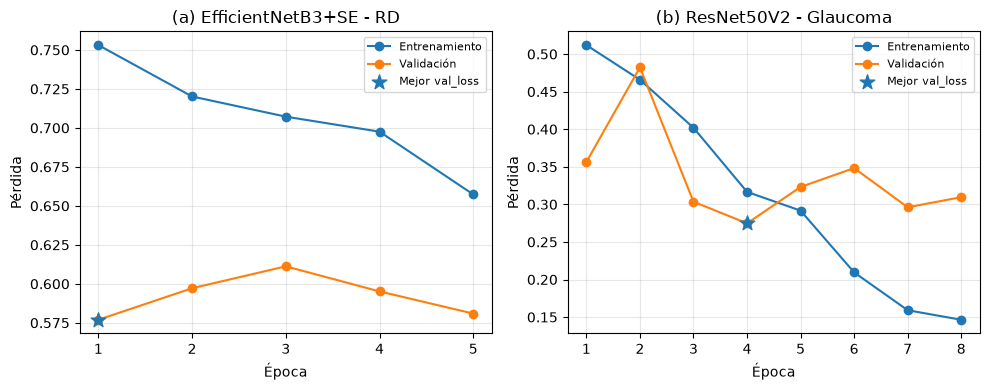

In [36]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)

# (a) EfficientNetB3+SE - Retinopatía Diabética

axes[0].plot(
    rd_history["epoch_plot"],
    rd_history["loss"],
    marker="o",
    label="Entrenamiento"
)

axes[0].plot(
    rd_history["epoch_plot"],
    rd_history["val_loss"],
    marker="o",
    label="Validación"
)

axes[0].scatter(
    rd_best_epoch,
    rd_best_val_loss,
    marker="*",
    s=120,
    zorder=5,
    label="Mejor val_loss"
)

axes[0].set_title(
    "(a) EfficientNetB3+SE - RD"
)

axes[0].set_xlabel(
    "Época"
)

axes[0].set_ylabel(
    "Pérdida"
)

axes[0].set_xticks(
    rd_history["epoch_plot"]
)

axes[0].grid(
    alpha=0.3
)

axes[0].legend(
    fontsize=8
)


# (b) ResNet50V2 - Glaucoma

axes[1].plot(
    glaucoma_history["epoch_plot"],
    glaucoma_history["loss"],
    marker="o",
    label="Entrenamiento"
)

axes[1].plot(
    glaucoma_history["epoch_plot"],
    glaucoma_history["val_loss"],
    marker="o",
    label="Validación"
)

axes[1].scatter(
    glaucoma_best_epoch,
    glaucoma_best_val_loss,
    marker="*",
    s=120,
    zorder=5,
    label="Mejor val_loss"
)

axes[1].set_title(
    "(b) ResNet50V2 - Glaucoma"
)

axes[1].set_xlabel(
    "Época"
)

axes[1].set_ylabel(
    "Pérdida"
)

axes[1].set_xticks(
    glaucoma_history["epoch_plot"]
)

axes[1].grid(
    alpha=0.3
)

axes[1].legend(
    fontsize=8
)


# Ajuste general

fig.tight_layout()

plt.show()

### Guardar automáticamente el visual

In [37]:
fig.tight_layout()

PNG_PATH = OUTPUT_DIR / "finetuning_loss.png"
PDF_PATH = OUTPUT_DIR / "finetuning_loss.pdf"

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

print("PNG guardado en:", PNG_PATH)
print("PDF guardado en:", PDF_PATH)

plt.show()

PNG guardado en: /mnt/c/Users/SeuNg720/Documents/TP1-RetiScan/results/paper/finetuning_loss.png
PDF guardado en: /mnt/c/Users/SeuNg720/Documents/TP1-RetiScan/results/paper/finetuning_loss.pdf
